In [31]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt




In [32]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier


In [33]:
# 1. LOAD DATA
possible_paths = ["/home/patel-krish/anaconda3/BrainyBeam/heart.csv"]
data_path = next((p for p in possible_paths if os.path.isfile(p)), None)

if data_path is None:
    raise FileNotFoundError(
        "Cannot find heart(2).csv. Put it beside the notebook or set data_path "
        "to the full path of your CSV file."
    )

df = pd.read_csv(data_path)
df.columns = df.columns.str.strip()

target_column = "target"
if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' was not found. Columns: {list(df.columns)}"
    )

df = df.drop_duplicates().reset_index(drop=True)
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df = df.dropna().reset_index(drop=True)

X = df.drop(columns=[target_column]).to_numpy(dtype=float)
y = df[target_column].to_numpy()

if len(np.unique(y)) != 2:
    raise ValueError(f"Expected a binary target; found classes {np.unique(y)}")

print("Dataset:", data_path)
print("Rows after cleaning:", len(df))
print("Number of features:", X.shape[1])
print("Target class counts:")
print(pd.Series(y).value_counts().sort_index().to_string())



Dataset: /home/patel-krish/anaconda3/BrainyBeam/heart.csv
Rows after cleaning: 302
Number of features: 13
Target class counts:
0    138
1    164


In [34]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTraining rows:", len(y_train))
print("Test rows:", len(y_test))


Training rows: 241
Test rows: 61


In [35]:
# 3. DEFINE AND TRAIN MODELS
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42, max_depth=5
    ),
    "k-NN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

test_predictions = {}
test_probabilities = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    test_predictions[name] = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)
        if hasattr(model, "classes_"):
            class_order = list(model.classes_)
        else:
            final_estimator = list(model.named_steps.values())[-1]
            class_order = list(final_estimator.classes_)
        positive_index = class_order.index(1) if 1 in class_order else -1
        test_probabilities[name] = probabilities[:, positive_index]

print("\nModels trained and predictions generated:")
for name in test_predictions:
    print("-", name)


Models trained and predictions generated:
- Logistic Regression
- Random Forest
- SVM
- Decision Tree
- k-NN


In [36]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    if len(y_true) != len(y_pred):
        raise ValueError("y_true and y_pred must have the same length.")

    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))

    accuracy = (tp + tn) / len(y_true) if len(y_true) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    return {
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "Accuracy": accuracy, "Precision": precision,
        "Recall": recall, "Specificity": specificity, "F1": f1
    }



In [37]:

def manual_auc(y_true, scores):
    y_true = np.asarray(y_true).ravel()
    scores = np.asarray(scores).ravel()
    positives = int(np.sum(y_true == 1))
    negatives = int(np.sum(y_true == 0))
    if positives == 0 or negatives == 0:
        return np.nan

    order = np.argsort(scores, kind="mergesort")
    sorted_scores = scores[order]
    ranks = np.empty(len(scores), dtype=float)
    i = 0
    while i < len(scores):
        j = i + 1
        while j < len(scores) and sorted_scores[j] == sorted_scores[i]:
            j += 1
        average_rank = ((i + 1) + j) / 2.0
        ranks[order[i:j]] = average_rank
        i = j

    positive_rank_sum = float(np.sum(ranks[y_true == 1]))
    return (positive_rank_sum - positives * (positives + 1) / 2) / (positives * negatives)



In [38]:
for name, predictions in test_predictions.items():
    row = {"Model": name}
    row.update(calculate_metrics(y_test, predictions))
    row["ROC-AUC"] = (
        manual_auc(y_test, test_probabilities[name])
        if name in test_probabilities else np.nan
    )
    rows.append(row)

results = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
print("\nMODEL PERFORMANCE SUMMARY")
print(results.round(4).to_string(index=False))
results.to_csv("all_model_performance_summary.csv", index=False)
print("\nSaved: all_model_performance_summary.csv")




MODEL PERFORMANCE SUMMARY
              Model  TP  TN  FP  FN  Accuracy  Precision  Recall  Specificity     F1  ROC-AUC
               k-NN  28  20   8   5    0.7869     0.7778  0.8485       0.7143 0.8116   0.8377
Logistic Regression  27  21   7   6    0.7869     0.7941  0.8182       0.7500 0.8060   0.8734
      Random Forest  26  21   7   7    0.7705     0.7879  0.7879       0.7500 0.7879   0.8723
      Decision Tree  25  22   6   8    0.7705     0.8065  0.7576       0.7857 0.7812   0.8317
                SVM  26  20   8   7    0.7541     0.7647  0.7879       0.7143 0.7761   0.8366

Saved: all_model_performance_summary.csv


In [39]:

def mcnemar_test(y_true, pred_a, pred_b):
    y_true = np.asarray(y_true).ravel()
    pred_a = np.asarray(pred_a).ravel()
    pred_b = np.asarray(pred_b).ravel()
    correct_a = pred_a == y_true
    correct_b = pred_b == y_true
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    discordant = b + c

    if discordant == 0:
        p_value = 1.0
    else:
        smaller = min(b, c)
        p_value = min(
            1.0,
            2.0 * sum(math.comb(discordant, k) for k in range(smaller + 1))
            / (2 ** discordant)
        )
    return {
        "A correct, B wrong": b,
        "A wrong, B correct": c,
        "Discordant pairs": discordant,
        "p_value": p_value
    }

best_name = results.iloc[0]["Model"]
significance_rows = []
for name, predictions in test_predictions.items():
    if name == best_name:
        continue
    test_result = mcnemar_test(y_test, test_predictions[best_name], predictions)
    significance_rows.append({
        "Reference Model": best_name,
        "Compared Model": name,
        **test_result,
        "Significant at 0.05": test_result["p_value"] < 0.05
    })

significance_df = pd.DataFrame(significance_rows)
print("\nPAIRED McNEMAR TESTS")
if significance_df.empty:
    print("At least two models are required.")
else:
    print(significance_df.round(4).to_string(index=False))
    significance_df.to_csv("manual_significance_tests.csv", index=False)
    print("\nSaved: manual_significance_tests.csv")




PAIRED McNEMAR TESTS
Reference Model      Compared Model  A correct, B wrong  A wrong, B correct  Discordant pairs  p_value  Significant at 0.05
           k-NN Logistic Regression                   3                   3                 6      1.0                False
           k-NN       Random Forest                   3                   2                 5      1.0                False
           k-NN                 SVM                   2                   0                 2      0.5                False
           k-NN       Decision Tree                   5                   4                 9      1.0                False

Saved: manual_significance_tests.csv


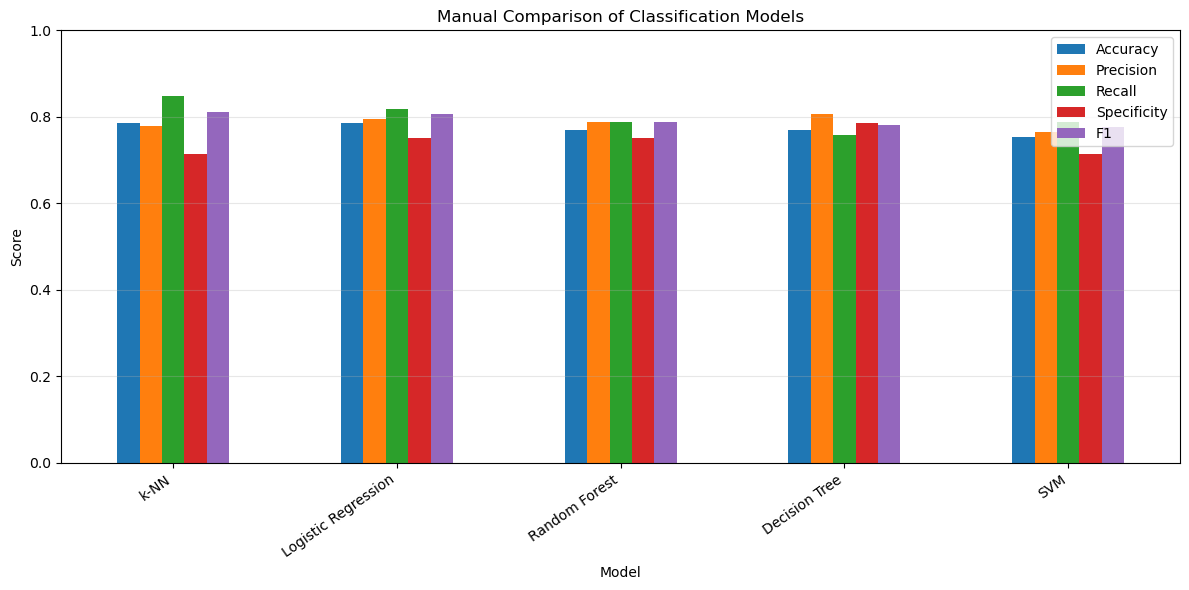

In [40]:

metric_columns = ["Accuracy", "Precision", "Recall", "Specificity", "F1"]
results.set_index("Model")[metric_columns].plot(kind="bar", figsize=(12, 6))
plt.ylabel("Score")
plt.title("Manual Comparison of Classification Models")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



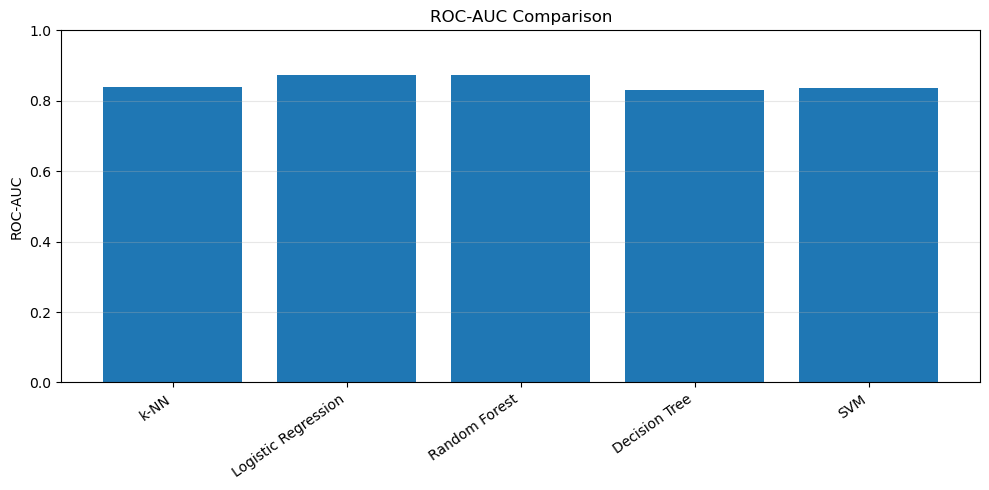

In [41]:

auc_results = results.dropna(subset=["ROC-AUC"])
if not auc_results.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(auc_results["Model"], auc_results["ROC-AUC"])
    plt.ylabel("ROC-AUC")
    plt.title("ROC-AUC Comparison")
    plt.ylim(0, 1)
    plt.xticks(rotation=35, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("\nROC-AUC plot skipped: no probability scores are available.")



In [42]:

best_row = results.iloc[0]
print("\nBEST MODEL BASED ON F1 SCORE")
print("Model:", best_row["Model"])
for metric in ["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC"]:
    value = best_row[metric]
    if pd.notna(value):
        print(f"{metric}: {value:.4f}")

print(
    "\nReminder: this ranks models by F1. Review precision and recall too. "
    "This coursework comparison is not a clinical diagnostic tool."
)




BEST MODEL BASED ON F1 SCORE
Model: k-NN
Accuracy: 0.7869
Precision: 0.7778
Recall: 0.8485
Specificity: 0.7143
F1: 0.8116
ROC-AUC: 0.8377

Reminder: this ranks models by F1. Review precision and recall too. This coursework comparison is not a clinical diagnostic tool.
